# RBC representation benchmark

## 1. Setup

### 1.1 Environment Setup and Imports

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent.parent.parent
sys.path.insert(0, str(project_root))
print("Project root:", project_root)

Project root: /home/verve/Project/research/MorphCell


In [2]:
import numpy as np
from sklearn.metrics import confusion_matrix

from utils import (
    build_analysis_features,
    evaluate_feature_sets,
    load_feature_output,
    plot_confusion_matrix,
    plot_metric_comparison,
    save_results_table,
    summarize_labels,
    validate_feature_label_pair,
)

### 1.2 Configuration

In [3]:
seed = 42
PCA_DIMS = 30
LAMBDA_VALUES = [0.0, 0.5, 1.0, 1.5]
KNN_NEIGHBORS = 5
N_SPLITS = 5
N_REPEATS = 10

label2name = {
    0: "discocyte",
    1: "echinocyte1",
    2: "echinocyte2",
    3: "echinocyte3",
    4: "stomatocyte",
    5: "spherocyte",
    6: "knizocyte",
}

feature_output_dir = project_root / "outputs/experiments/rbc/features"
data_dir = project_root / "notebooks/rbc/03_benchmark/data"
output_dir = project_root / "outputs/experiments/rbc/benchmark"
output_dir.mkdir(parents=True, exist_ok=True)

## 2. Load inputs

MorphCell features, class labels, sample IDs, and physical scale come from the
`morphcell_cross+self` extraction output. DFN and RI-PC use their respective
extraction outputs, aligned by sample ID and checked against the reference labels.

Biophysical descriptors and the SPHARM spectrum are read directly from `data/`.
Their shared row IDs must match the reference IDs in the same order.

In [4]:
morphcell_dir = feature_output_dir / "morphcell_cross+self"
ids = np.load(morphcell_dir / "ids.npy")
labels = np.load(morphcell_dir / "labels.npy")
morphcell_features = load_feature_output(
    morphcell_dir, "concated_features.npy", ids, labels
)
scales, labels = validate_feature_label_pair(
    np.load(morphcell_dir / "scales.npy"), labels, feature_name="physical scale"
)
if scales.shape[1] != 1:
    raise ValueError("Physical scale must have one column")

dfn_features = load_feature_output(
    feature_output_dir / "dfn_dgcnn", "features.npy", ids, labels
)
ri_pc_features = load_feature_output(
    feature_output_dir / "cytodl_point", "features.npy", ids, labels
)

descriptor_ids = np.load(data_dir / "ids.npy")
np.testing.assert_array_equal(descriptor_ids, ids)

biophysical_features = np.load(data_dir / "morph.npy")
spharm_features = np.load(data_dir / "norm_s.npy")

display(summarize_labels(labels, label2name=label2name))

,label,count,class_name
0,0,192,discocyte
1,1,27,echinocyte1
2,2,131,echinocyte2
3,3,120,echinocyte3
4,4,35,stomatocyte
5,5,93,spherocyte
6,6,22,knizocyte


## 3. Evaluate the paper comparisons

Use distance-weighted Euclidean 5-NN with repeated stratified 5-fold
cross-validation (10 repeats, seed 42). Report balanced accuracy and macro-F1
as mean ± sample standard deviation over the 50 splits.

In [5]:
feature_registry = {}
for lambda_weight in LAMBDA_VALUES:
    feature_registry[f"MorphCell (λ={lambda_weight:g})"] = {
        "features": build_analysis_features(
            morphcell_features,
            scales=scales,
            lambda_weight=lambda_weight,
            apply_pca=True,
            pca_components=PCA_DIMS,
        ),
        "standardize_for_knn": False,
    }

feature_registry.update(
    {
        "Physical scale": {
            "features": build_analysis_features(
                np.zeros((len(scales), 0)), scales=scales, lambda_weight=1.0
            ),
            "standardize_for_knn": False,
        },
        "Biophysical descriptors": {
            "features": biophysical_features,
            "standardize_for_knn": True,
        },
        "SPHARM": {"features": spharm_features, "standardize_for_knn": False},
        "DFN": {"features": dfn_features, "standardize_for_knn": False},
        "RI-PC": {"features": ri_pc_features, "standardize_for_knn": False},
    }
)

for name, config in feature_registry.items():
    print(f"{name}: {config['features'].shape}")

MorphCell (λ=0): (620, 30)
MorphCell (λ=0.5): (620, 31)
MorphCell (λ=1): (620, 31)
MorphCell (λ=1.5): (620, 31)
Physical scale: (620, 1)
Biophysical descriptors: (620, 22)
SPHARM: (620, 17)
DFN: (620, 512)
RI-PC: (620, 512)


In [6]:
summary_df, detailed_results = evaluate_feature_sets(
    feature_registry=feature_registry,
    labels=labels,
    n_neighbors=KNN_NEIGHBORS,
    n_splits=N_SPLITS,
    n_repeats=N_REPEATS,
    random_state=seed,
)
summary_df

,feature_set,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std,n_folds,feature_dim,standardize_for_knn
0,MorphCell (λ=0),0.868117,0.022652,0.875119,0.029910,50,30,False
1,MorphCell (λ=0.5),0.853858,0.027645,0.861988,0.035916,50,31,False
2,MorphCell (λ=1),0.834458,0.032159,0.847088,0.035636,50,31,False
7,DFN,0.827682,0.024976,0.825743,0.029402,50,512,False
3,MorphCell (λ=1.5),0.803451,0.036518,0.815559,0.039024,50,31,False
6,SPHARM,0.759705,0.046589,0.767311,0.045945,50,17,False
5,Biophysical descriptors,0.757009,0.047369,0.779236,0.050143,50,22,True
8,RI-PC,0.622271,0.036600,0.642091,0.046043,50,512,False
4,Physical scale,0.272836,0.029914,0.268553,0.030480,50,1,False


✓ Results table saved to: /home/verve/Project/research/MorphCell/outputs/experiments/rbc/benchmark/summary_metrics.csv
✓ Metric comparison saved to: /home/verve/Project/research/MorphCell/outputs/experiments/rbc/benchmark/metric_comparison.svg


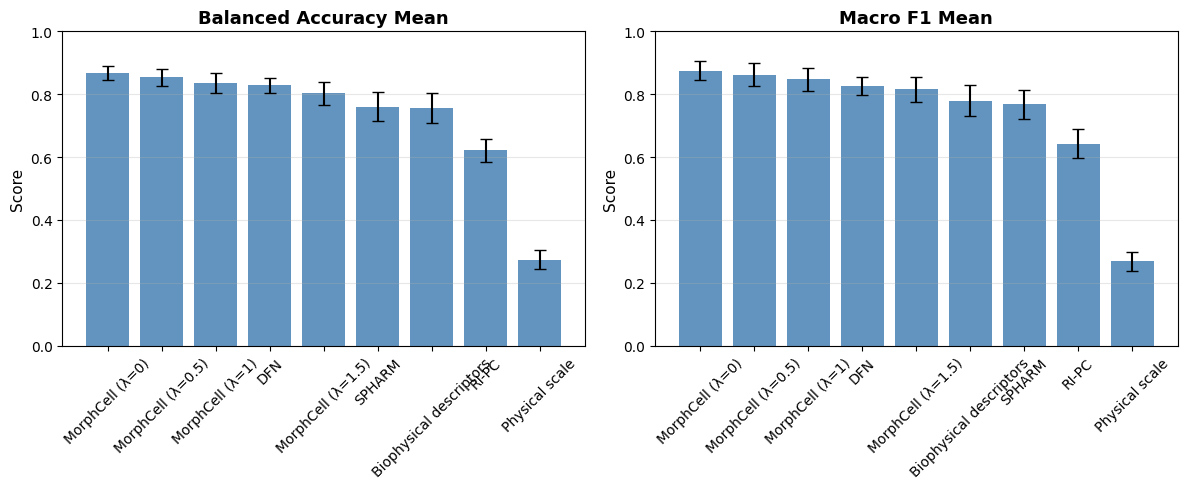

In [7]:
save_results_table(summary_df, output_dir / "summary_metrics.csv")
plot_metric_comparison(
    summary_df,
    save_path=output_dir / "metric_comparison.svg",
)

## 4. Shape-driven MorphCell confusion matrix

✓ Confusion matrix saved to: /home/verve/Project/research/MorphCell/outputs/experiments/rbc/benchmark/morphcell_lambda_0_confusion_matrix.svg


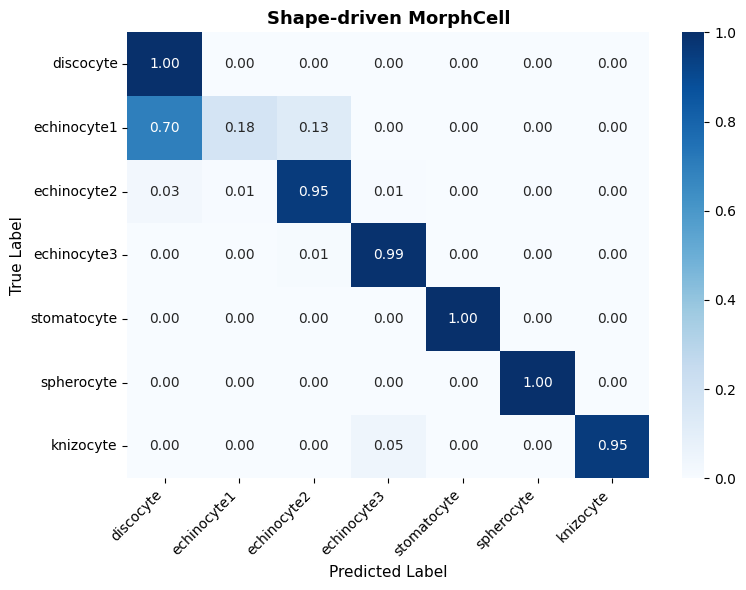

In [8]:
result = detailed_results["MorphCell (λ=0)"]
plot_confusion_matrix(
    result["y_true"],
    result["y_pred"],
    label2name=label2name,
    normalize=True,
    title="Shape-driven MorphCell",
    save_path=output_dir / "morphcell_lambda_0_confusion_matrix.svg",
)

labels_sorted = np.unique(result["y_true"])
cm_raw = confusion_matrix(result["y_true"], result["y_pred"], labels=labels_sorted)
label_names = np.array([label2name[label] for label in labels_sorted])
np.save(output_dir / "morphcell_lambda_0_confusion_matrix_raw.npy", cm_raw)
np.save(output_dir / "morphcell_lambda_0_confusion_matrix_labels.npy", label_names)